# Notizbuch zum Analysieren und verstehen des MNIST HAM10000 Datensatz

**Autoren**
- [1] Noel Codella, Veronica Rotemberg, Philipp Tschandl, M. Emre Celebi, Stephen Dusza, David Gutman, Brian Helba, Aadi Kalloo, Konstantinos Liopyris, Michael Marchetti, Harald Kittler, Allan Halpern: "Skin Lesion Analysis Toward Melanoma Detection 2018: A Challenge Hosted by the International Skin Imaging Collaboration (ISIC)", 2018; https://arxiv.org/abs/1902.03368
- [2] Tschandl, P., Rosendahl, C. & Kittler, H. The HAM10000 dataset, a large collection of multi-source dermatoscopic images of common pigmented skin lesions. Sci. Data 5, 180161 doi:10.1038/sdata.2018.161 (2018).

**Generelle Eckdaten**
- verwendet für den ISIC 2018 Wettkampf 
    - Subziele: Umriss der Hautläsion erkennen, Läsionen-Mekmale feststellen (z.B. gepunktet, Streifen etc.), Labeln von Hautläsionen
- eine Metadaten Datei (`HAM10000_metadata.csv`) mit Spalten `lesion_id`, `image_id`, `dx` (Diagnose), `dx_type` (Diagnose-Methode), `age` (Alter), `sex` (Geschlecht), `localization` (Körperteil)
- zwei Ordner mit Bilder (600x450) entsprechend image_id
- 4 .csv Dateien mit komprimierten Pixelrohwerten (sowohl '8x8' als auch '28x28') und `dx`-Label für RGB und HLS (?)

**Diagnose-Typen (`dx`)**
- `nv`: Melanocytic nevi (Melanozytärer Nävus / gewöhnliches Muttermal)
- `mel`: Melanoma (Melanom / schwarzer Hautkrebs)
- `bkl`: Benign keratosis-like lesions (Gutartige Keratose-ähnliche Läsionen)
- `bcc`: Basal cell carcinoma (Basalzellkarzinom)
- `akiec`: Actinic keratoses / Intraepithelial carcinoma (Aktinische Keratose / intraepitheliales Karzinom)
- `vasc`: Vascular lesions (Vaskuläre Läsionen)
- `df`: Dermatofibroma (Dermatofibrom)

**Diagnose-Methoden (`dx_type`)**
- `histo`: Histopathologisch bestätigt (durch Gewebeuntersuchung)
- `follow_up`: Durch Verlaufskontrolle bestätigt
- `consensus`: Durch Expertenkonsens bestätigt
- `confocal`: Durch konfokale Mikroskopie bestätigt

## Imports und dataframe aufbauen

In [ ]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

current_dir = Path.cwd()
proj_dir = current_dir.parent.parent.resolve() # get project root directory

print(f"Project directory set to: {proj_dir}")

# Add the project root to the system path to import local modules
sys.path.append(str(proj_dir / 'python'))

In [ ]:
from dataset_manager import DatasetManager

# Initialize the dataset manager
dataset_manager = DatasetManager(data_dir=Path(proj_dir) / "data")

# Load the cleaned metadata (without melanoma filter to see all lesion types)
dataset_manager.load_cleaned_metadata(filter_melanoma_only=False)

# Get the dataframe
df = dataset_manager.df
print(f"Loaded {len(df)} samples")
df.head()

Loaded 10013 samples


,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,lesion_idx,image_hash
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/home/vertyx/Documents/dermascan/data/raw/ISIC...,2,7435288631440057672
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/home/vertyx/Documents/dermascan/data/raw/ISIC...,2,-9115187500910267718
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/home/vertyx/Documents/dermascan/data/raw/ISIC...,2,7322212600189289879
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/home/vertyx/Documents/dermascan/data/raw/ISIC...,2,9126135107283127674
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/home/vertyx/Documents/dermascan/data/raw/ISIC...,2,-3721980262532896314


**Leere Daten filtern** 

In [16]:
# Check for missing values
print("Missing values:\n", df.isnull().sum())

# The dataset manager already handles missing values in the cleaned metadata
# Extract features and target for potential model training
features = df.drop(columns=['lesion_idx'], axis=1, errors='ignore')
target = df['lesion_idx'] if 'lesion_idx' in df.columns else None

print(f"\nFeatures shape: {features.shape}")
if target is not None:
    print(f"Target shape: {target.shape}")

Missing values:
 lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
image_path       0
lesion_idx       0
image_hash       0
dtype: int64

Features shape: (10013, 9)
Target shape: (10013,)


## Visualisierung des gesamten Datensatzes

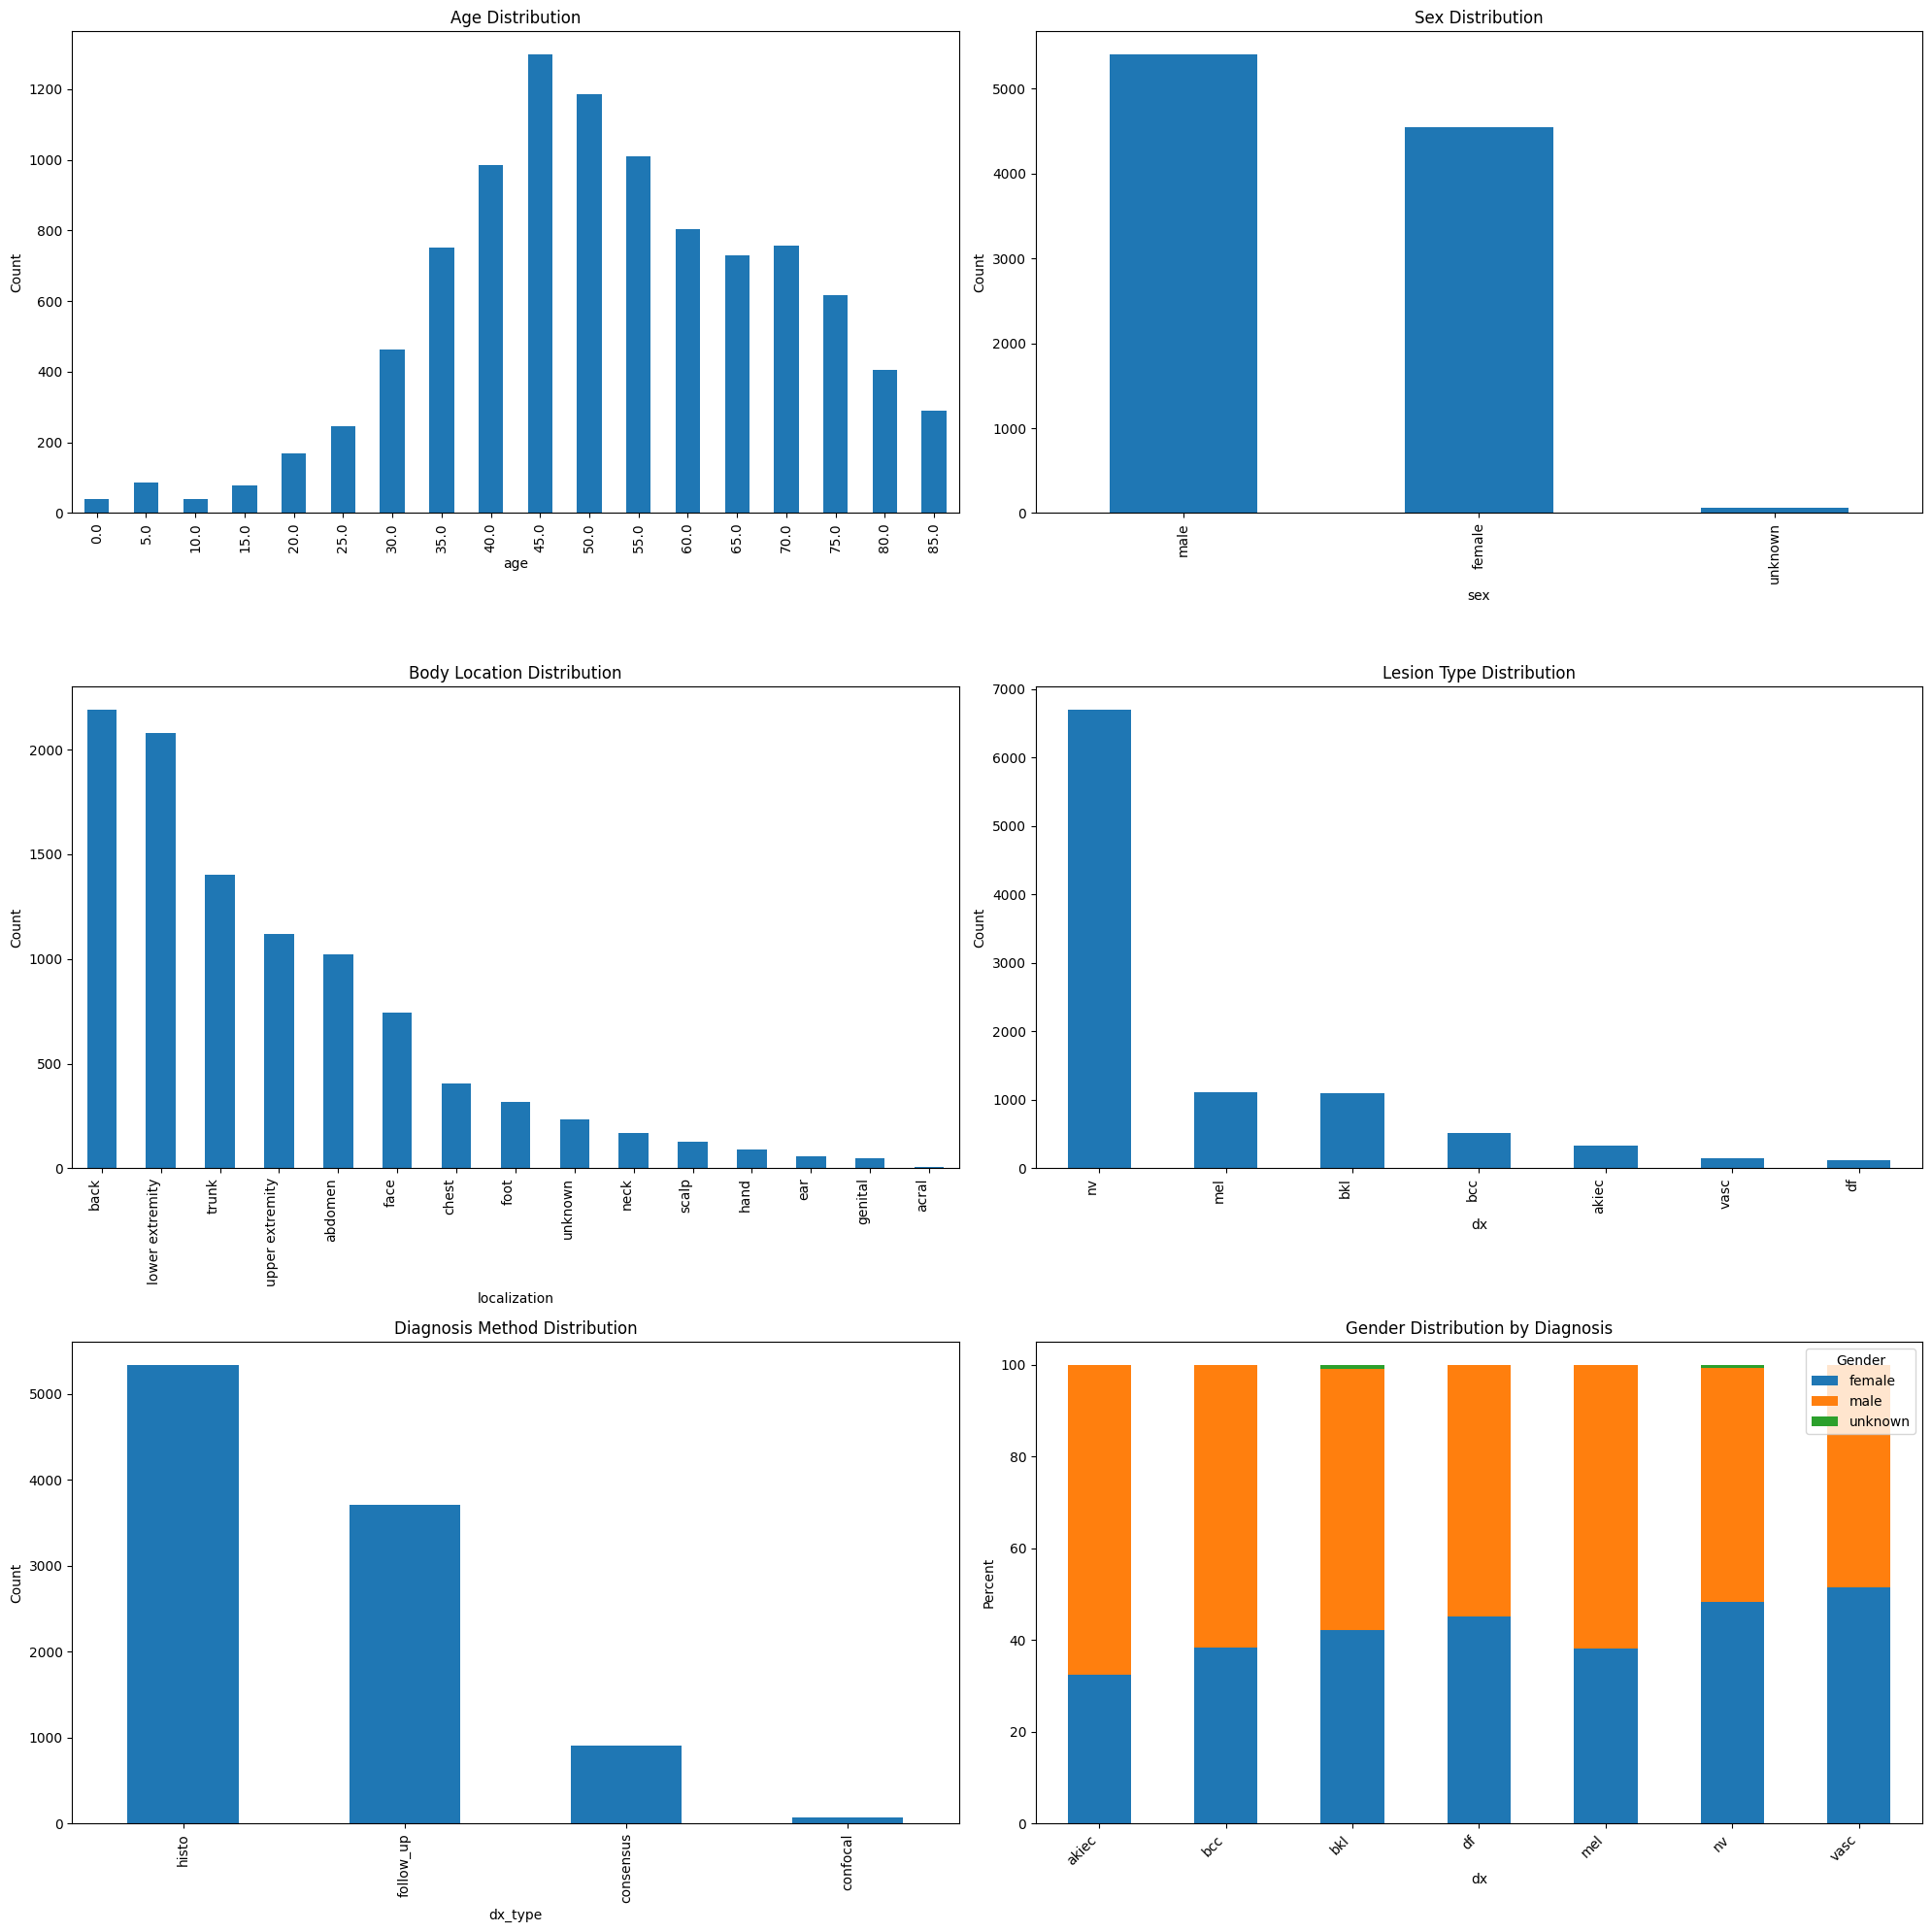

In [17]:
plt.figure(figsize=(20,20))
plt.subplots_adjust(left=0.125, bottom=0.1, right=0.9, top=0.9, hspace=0.4, wspace=0.3)

plt.subplot(3,2,1)
plt.ylabel("Count")
plt.xlabel("Age")
df['age'].value_counts().sort_index().plot.bar()
plt.title("Age Distribution")

plt.subplot(3,2,2)
plt.ylabel("Count")
plt.xlabel("Sex")
df['sex'].value_counts().plot.bar()
plt.title("Sex Distribution")

plt.subplot(3,2,3)
plt.ylabel("Count")
plt.xlabel("Localization")
plt.xticks(rotation=45, ha='right')
df['localization'].value_counts().plot.bar()
plt.title("Body Location Distribution")

plt.subplot(3,2,4)
plt.ylabel("Count")
plt.xlabel("Diagnosis")
plt.xticks(rotation=45, ha='right')
df['dx'].value_counts().plot.bar()
plt.title("Lesion Type Distribution")

plt.subplot(3,2,5)
plt.ylabel("Count")
plt.xlabel("Diagnosis Type")
df['dx_type'].value_counts().plot.bar()
plt.title("Diagnosis Method Distribution")

plt.subplot(3,2,6)
plt.ylabel("Percent")
plt.xlabel("Diagnosis")
gender_diag = pd.crosstab(df['dx'], df['sex'], normalize='index') * 100
gender_diag.plot(kind='bar', stacked=True, ax=plt.gca())
plt.legend(title='Gender')
plt.title("Gender Distribution by Diagnosis")
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

## Reduced work order - Focus on melanomas and nevi

In [18]:
dataset_manager.load_cleaned_metadata(filter_melanoma_only=True)
reduced_df = dataset_manager.df

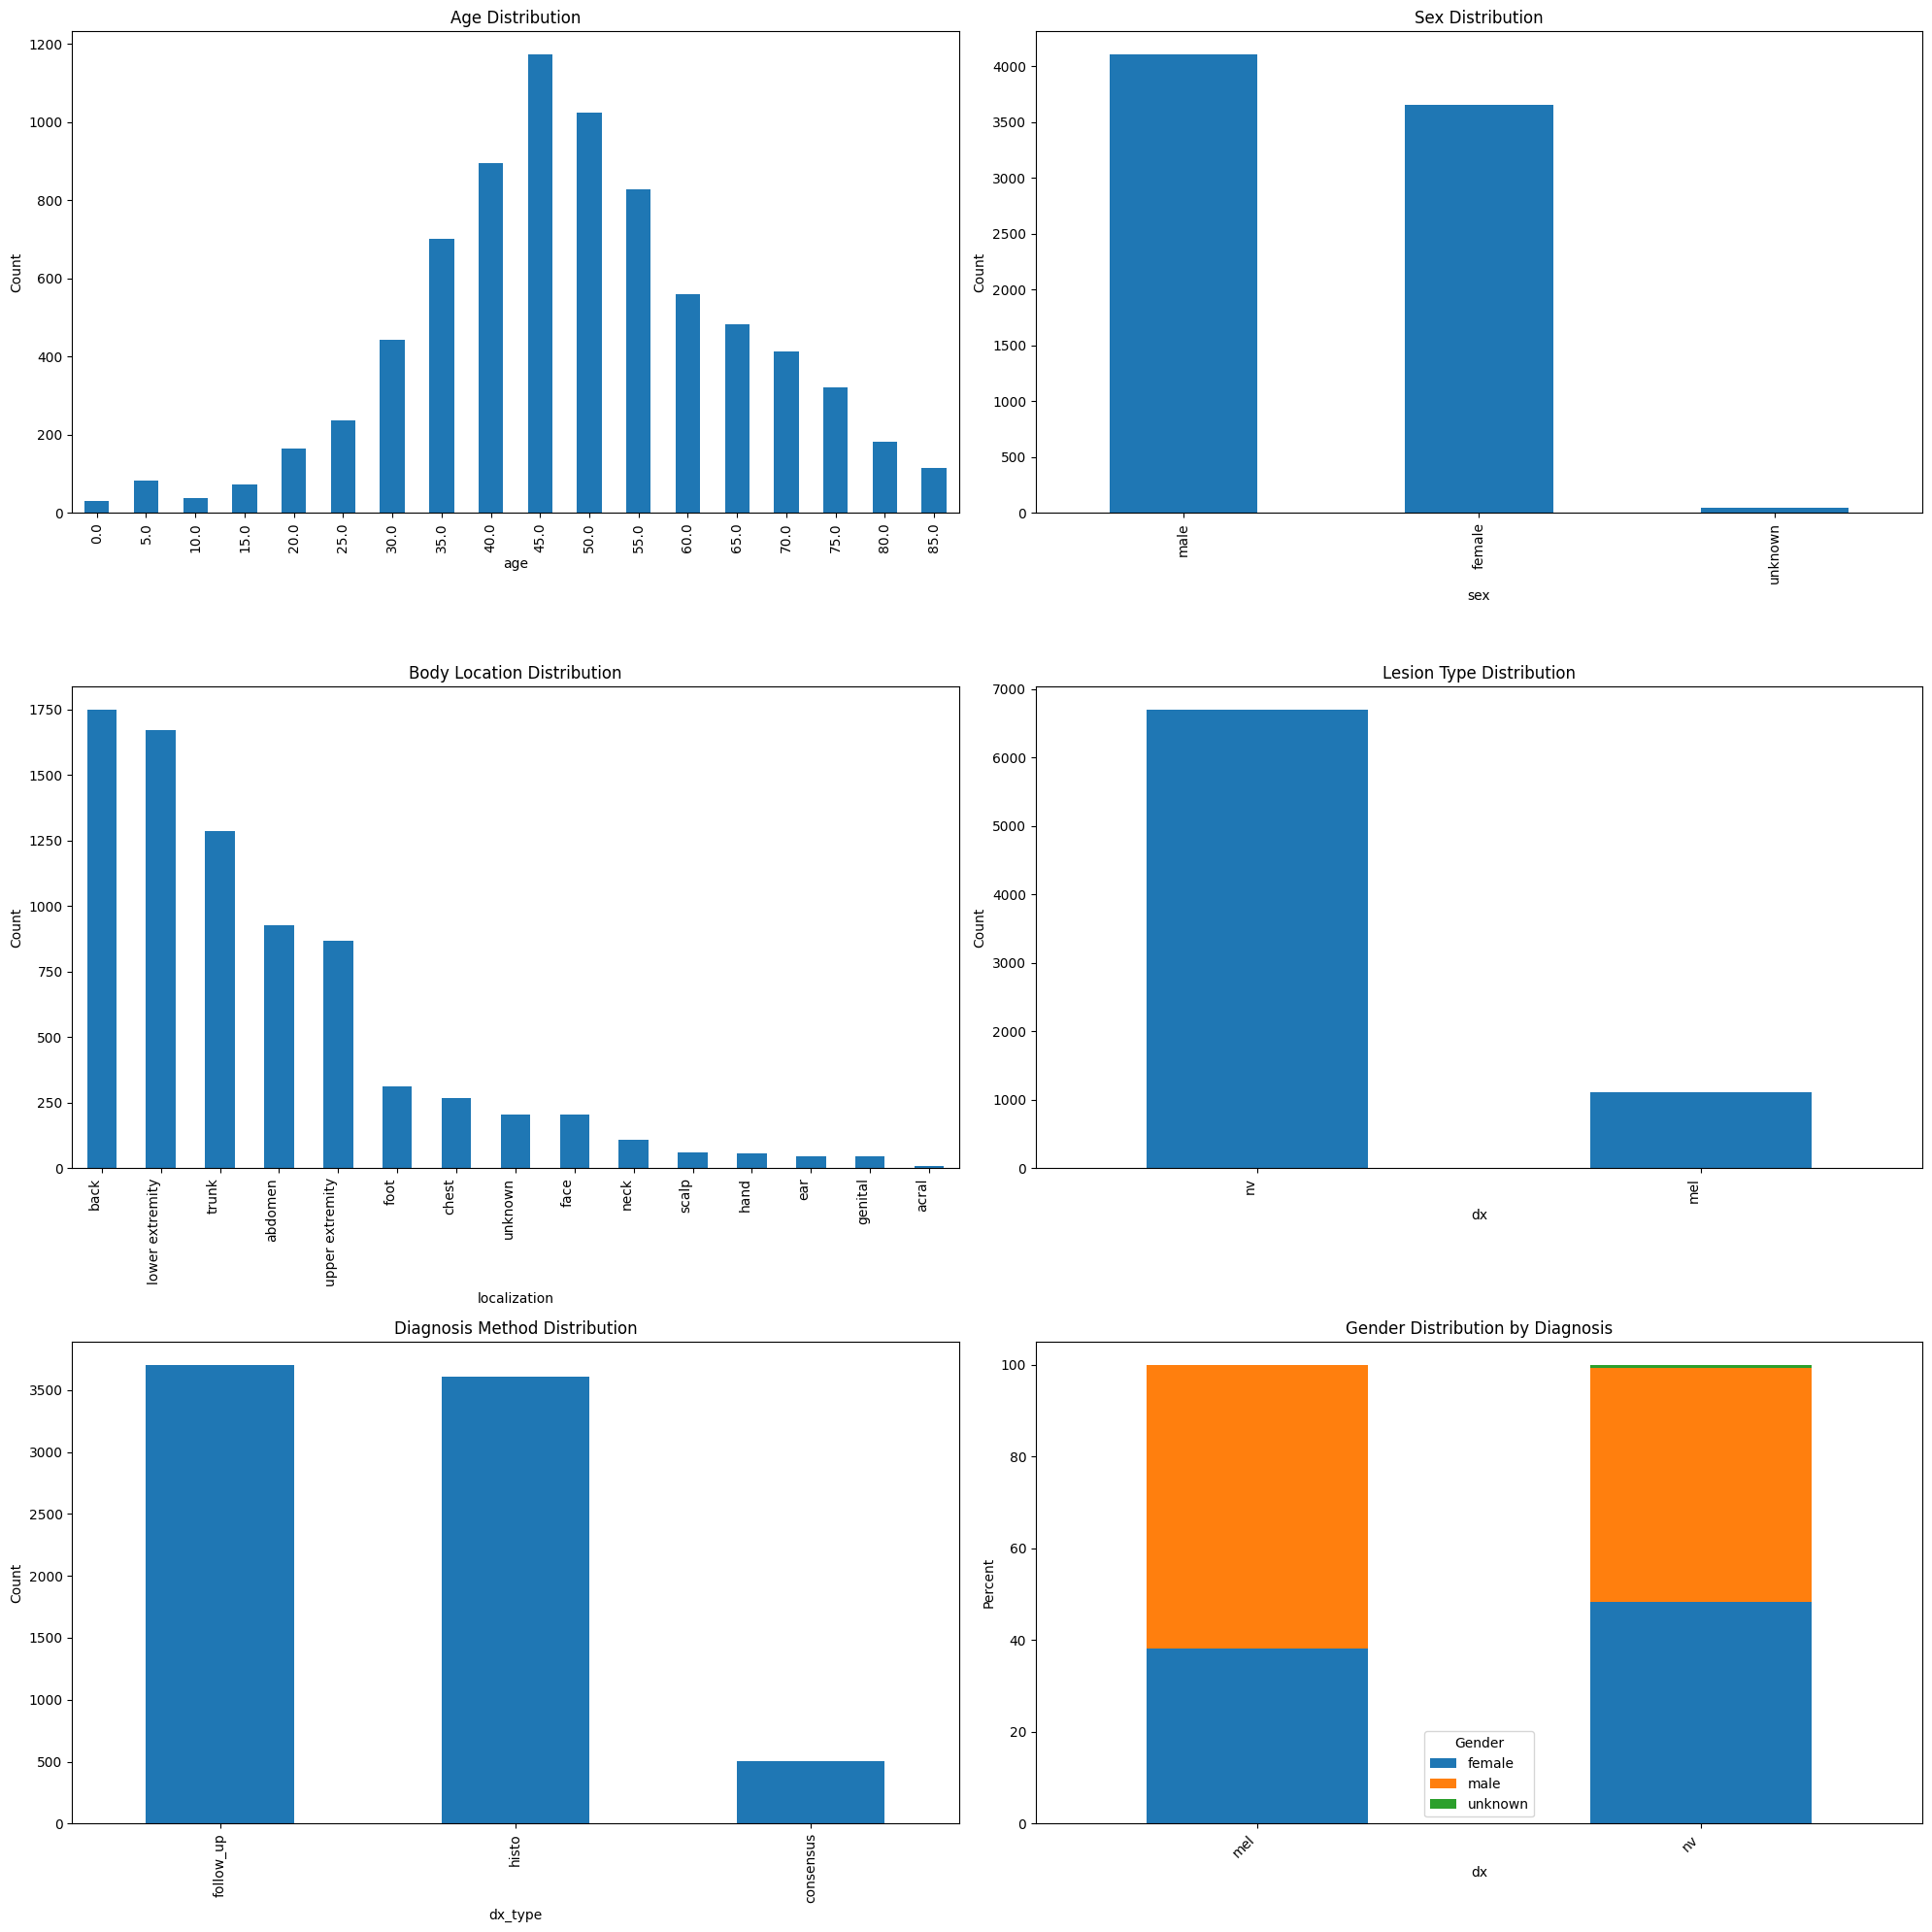

In [19]:
plt.figure(figsize=(20,20))
plt.subplots_adjust(left=0.125, bottom=0.1, right=0.9, top=0.9, hspace=0.4, wspace=0.3)

plt.subplot(3,2,1)
plt.ylabel("Count")
plt.xlabel("Age")
reduced_df['age'].value_counts().sort_index().plot.bar()
plt.title("Age Distribution")

plt.subplot(3,2,2)
plt.ylabel("Count")
plt.xlabel("Sex")
reduced_df['sex'].value_counts().plot.bar()
plt.title("Sex Distribution")

plt.subplot(3,2,3)
plt.ylabel("Count")
plt.xlabel("Localization")
plt.xticks(rotation=45, ha='right')
reduced_df['localization'].value_counts().plot.bar()
plt.title("Body Location Distribution")

plt.subplot(3,2,4)
plt.ylabel("Count")
plt.xlabel("Diagnosis")
plt.xticks(rotation=45, ha='right')
reduced_df['dx'].value_counts().plot.bar()
plt.title("Lesion Type Distribution")

plt.subplot(3,2,5)
plt.ylabel("Count")
plt.xlabel("Diagnosis Type")
reduced_df['dx_type'].value_counts().plot.bar()
plt.title("Diagnosis Method Distribution")

plt.subplot(3,2,6)
plt.ylabel("Percent")
plt.xlabel("Diagnosis")
gender_diag = pd.crosstab(reduced_df['dx'], reduced_df['sex'], normalize='index') * 100
gender_diag.plot(kind='bar', stacked=True, ax=plt.gca())
plt.legend(title='Gender')
plt.title("Gender Distribution by Diagnosis")
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()